<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    LNDb - Lung Nodule Database
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    A datased based on LIDC-IDRI
  </h3>

  <p>
   The LNDb was developed as an external dataset complimentary to LIDC-IDRI. There are a few important differences between the two... While LIDC-IDRI is a project shared between 7 institutions, LNDb is a smaller dataset, belonging to a single institution - Centro Hospitalar e Universitário de São João (CHUSJ) in Porto.
  </p>
  <p>
   LNDb contains 294 CT scans - about a quarter of the size of LIDC-IDRI, and its classification method is different as well: it uses a single-blind methodology (a radiologist would read the scan once and no consensus or review between the radiologists was performed), instead of having multiple radiologists reading the same scan. This might cause a noticeable distinction in classification pattern for each radiologist; but, unlike LIDC-IDRI, the 5 participant radiologists are identified uniformly throughout the dataset as R1, R2, R3, R4 and R5.
  </p>
  <p>
   The variability in acquisition parameters is significantly lower in LNDb, as well as the subjective characterization of nodules. LNDb is overall a more clinically realistic dataset. It also gives the opportunity to analyze gaze patterns, since eyetracking data is available.
   </p>
  
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Initial Data Analysis
  </h3>

  <p>
    To access LNDb's auxiliary functions, which will help us to visualize, understand and manipulate data, we must import the script <strong>'utils.py'</strong> and other scripts made available with the download of the dataset.
  </p>
  <p>
    The first step in our analysis of the dataset is to ensure that we can read the MetaImage <strong>.mhd/.raw</strong> medical image files - both the Computerized Tomography (CT) data and the segmentation masks are in this format. The file <strong>'utils.py'</strong> includes routines based on the SimpleITK library that allow us to... 
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Load the 3D CT images and the nodule masks.</li>
    <li style="margin-bottom: 8px;">Extract the metadata from the medical images, such as the pixel/voxel spacing, the origin and the orientation matrix of the CT.</li>
  </ol>
</div>

In [1]:
import os, sys
from pathlib import Path

root_path = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(root_path) not in sys.path:
    sys.path.append(str(root_path))

# Os scripts do LNDb importam-se entre si sem prefixo (ex: 'from utils import readCsv'),
# por isso a própria pasta src/lndb_utils também tem de estar no sys.path
lndb_utils_path = root_path / 'src' / 'lndb_utils'
if str(lndb_utils_path) not in sys.path:
    sys.path.append(str(lndb_utils_path))

from src.lndb_utils import utils
from src.lndb_utils.readNoduleList import nodEqDiam

def encontrar_ficheiro(nome_ficheiro, pasta_base="../data"):
    resultados = list(Path(pasta_base).rglob(nome_ficheiro))
    if not resultados:
        raise FileNotFoundError(f"Ficheiro '{nome_ficheiro}' não foi encontrado em '{pasta_base}'.")
    return str(resultados[0])


In [2]:
caminho_mhd = encontrar_ficheiro("LNDb-0001.mhd")
scan, spacing, origin, transfmat = utils.readMhd(caminho_mhd)
print(scan.shape, spacing, origin)


(328, 512, 512) (0.607421875, 0.607421875, 1.0) (-158.1962890625, -309.1962890625, -297.5)


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    By the shape of the scan array, we can conclude that it has 328 cuts of 512x512 pixels. The voxel spacing (0.607, 0.607, 1.0)mm shows that the volume <strong>is not isotropic</strong> because the plane resolution is thinner than in between cuts. This is something to have in mind if we decide to resample into a uniform spacing before feature extraction - this probably makes the most sense. 
  </p>
  <div style="background-color: #c25719; padding: 2px 10px; border-radius: 0px; margin: 0px -10px;">
    <strong style="color: #1967d2;">Note:</strong> An isotropic volume implies that the spacing between voxels is equal in all directions (x, y, z) - in other words, each voxel is shaped like a perfect cube.
  </div>
  <p>
    Lastly, the origin indicates the coordinate of the word corresponding to the volume corner, necessary to convert nodule coordinates in further steps.
  </p>
  <p>
    Our next goal is to understand the structure of the file <strong>'chars_trainNodules.csv'</strong>, which contains the subjective classifications of each nodule by the radiologists - including malignancy - before combining them with the coordinates.
    </p>
</div>

</div>

In [3]:
import pandas as pd
caminho_csv = encontrar_ficheiro("chars_trainNodules.csv")
df = pd.read_csv(caminho_csv)
df.head()

,LNDbID,RadID,FindingID,calcification,internalStructure,lobulation,malignancy,margin,sphericity,spiculation,subtlety
0,1.0,1.0,1.0,6.0,1.0,1.0,2.0,4.0,2.0,2.0,5.0
1,1.0,1.0,2.0,6.0,1.0,1.0,2.0,4.0,2.0,1.0,3.0
2,1.0,2.0,1.0,3.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0
3,1.0,3.0,1.0,5.0,1.0,2.0,2.0,3.0,4.0,3.0,4.0
4,2.0,1.0,1.0,6.0,1.0,1.0,1.0,5.0,3.0,1.0,5.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1527 entries, 0 to 1526
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   LNDbID             1527 non-null   float64
 1   RadID              1527 non-null   float64
 2   FindingID          1527 non-null   float64
 3   calcification      1527 non-null   float64
 4   internalStructure  1527 non-null   float64
 5   lobulation         1527 non-null   float64
 6   malignancy         1527 non-null   float64
 7   margin             1527 non-null   float64
 8   sphericity         1527 non-null   float64
 9   spiculation        1527 non-null   float64
 10  subtlety           1527 non-null   float64
dtypes: float64(11)
memory usage: 131.4 KB


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    We can conclude the following:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The file has <strong>1527</strong> entries and no missing values, which is good. However, we can observe that numeric columns are being categorized as type <strong>float64</strong>, which is something to be fixed;</li>
    <li style="margin-bottom: 8px;">Each line corresponds to a finding <strong>'FindingID'</strong> marked by a radiologist <strong>'RadID'</strong> in a scan <strong>'LNDbID'</strong>.</li>
    <li style="margin-bottom: 8px;">Includes the column <strong style="color: #c25719;">'malignancy'</strong>, which categorizes on a scale from 1 to 5 the overall probability assessment that the nodule is cancerous based on its size, growth rate, and combination of physical features. There are also other important characteristics regarding the physical aspect of the nodule, which contribute for the characterization of malignancy:
      <ol style="padding-left: 30px; margin-bottom: 0px;">
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Calcification</strong> refers to calcium deposits inside the nodule, which appear bright white on CT. When a nodule is benign, it is common to observe central, diffuse, laminated (concentric rings), or "popcorn" calcifications, which usually indicate past infections, granulomas, or hamartomas. However, if the calcification is eccentric (off-center) or stippled (tiny scattered specks), it can more frequently be linked to malignancy.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Internal Structure</strong> describes what the inside of the nodule consists of; specifically, its tissue density and components. If <strong>solid</strong>, it is dense throughout, completely obscuring lung tissue behind it. If <strong>subsolid / ground-glass (GGO)</strong>, it is a hazy area where underlying blood vessels and lung structures remain visible. If <strong>part-solid</strong>, it contains both solid and ground-glass areas. Finally, <strong>fat</strong> inside a nodule strongly favors a benign hamartoma, while thick-walled hollow centers - <strong>cavitation</strong> warrant careful evaluation.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Lobulation</strong> refers to an undulating, scalloped, or wave-like outer contour instead of a smooth circle. Lobulated margins occur due to uneven growth rates in different parts of the nodule and carry a moderate association with malignancy.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Margin</strong> is the general appearance of the border where the nodule meets normal lung tissue. If <strong>smooth / well-defined</strong>, it is typically a reassuring sign. If <strong>ill-defined / irregular</strong>, then it points towards malignancy.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Sphericity</strong> measures how closely the nodule resembles a 3D sphere versus an elongated or flat shape. Perfectly round nodules are less common, but highly irregular or asymmetric 3D shapes can reflect invasive growth.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Spiculation</strong> refers to strands or "spikes" radiating outward from the edge of the nodule into surrounding lung tissue, giving it a sunburst or starburst appearance. This is one of the strongest radiological signs associated with malignancy.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Subtlety</strong> indicates how easy or difficult the nodule is to visually distinguish from surrounding structures (like normal blood vessels, chest wall, or diaphragm). High subtlety means it is faint or hidden, while low subtlety means it stands out starkly.</li>
      </ol>
    </li>
    <li style="margin-bottom: 8px;">There are no (x, y, z) coordinates. To obtain them, we must connect this file to <strong>'trainNodules.csv'</strong>.</li>
  </ul>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Visualizing and locating a nodule in a scan
  </h3>

  <p>
    Our next goal is to validate the entire pipeline, from reading the coordinates of a nodule from <strong>'trainNodules.csv'</strong>, in milimeters, and converting them to image coordinates, in pixel / cut indexes, using the origin and transformation origin of the corresponding scan.
  </p>

</div>

In [5]:
import numpy as np

caminho_csv = encontrar_ficheiro("trainNodules.csv")
nodules = pd.read_csv(caminho_csv)
nod1 = nodules[nodules['LNDbID'] == 1].iloc[0]
xyz_world = np.array([nod1['x'], nod1['y'], nod1['z']])

transfmat_toimg, transfmat_toworld = utils.getImgWorldTransfMats(spacing, transfmat)
xyz_img = utils.convertToImgCoord(xyz_world, origin, transfmat_toimg)
print(xyz_img)

[187. 313. 260.]


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    As we can see, the result is in (x, y, z) format. The values make sense, as they are inside the volume limits (328x512x512).
  </p>
  <div style="background-color: #c25719; padding: 2px 10px; border-radius: 0px; margin: 0px -10px;">
    <strong style="color: #1967d2;">Note:</strong> the scan array is in (z, y, x) format, because there is a conversion difference between SimpleITK and NumPy that must not be forgotten. 
  </div>
  <p>
    Now, we must confirm visually the coordinate conversion by showing the exact cut where the nodule was annotated, with a red <strong>X</strong> in its position. Below, there is the side-by-side comparison of the original image and the annotated image.
  </p>

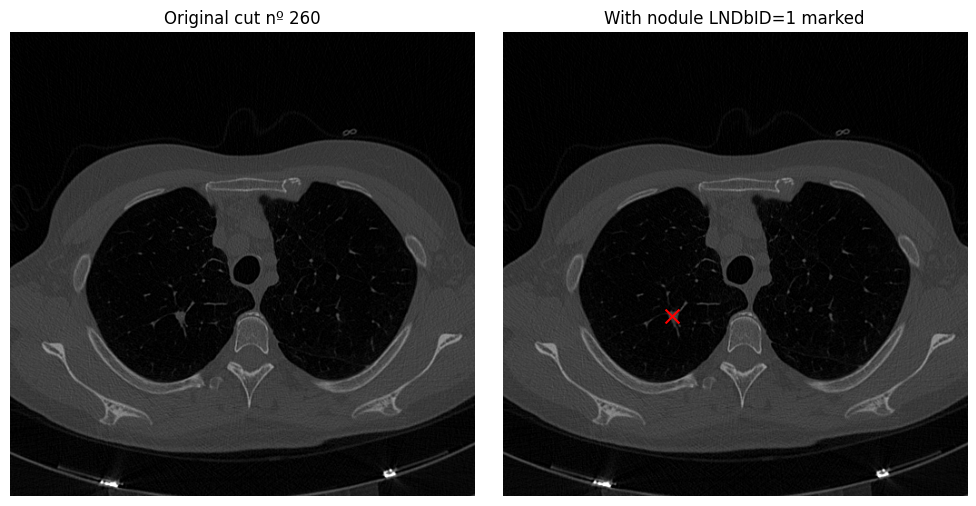

In [6]:
import matplotlib.pyplot as plt 
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

z_slice = int(xyz_img[2])  # o terceiro valor, correspondente ao corte
y_row = int(xyz_img[1])
x_col = int(xyz_img[0])

axes[0].imshow(scan[z_slice], cmap='gray')
axes[0].set_title(f"Original cut nº {z_slice}")
axes[0].axis("off")  # Hides x and y tick marks
axes[1].imshow(scan[z_slice], cmap='gray')
axes[1].set_title("With nodule LNDbID=1 marked")
axes[1].scatter(x_col, y_row, c='red', marker='x', s=100)  # marca a posição do nódulo
axes[1].axis("off")

# Adjust spacing and display
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    We can also test the function <strong>'extractCube'</strong>; it selects a fixed region around a coordinate, which we believe we can later use to train a model.
  </p>
</div>

(80, 80, 80)


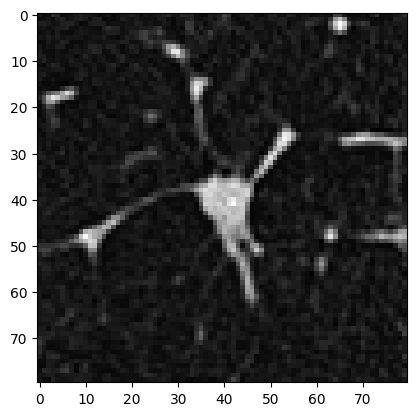

In [7]:
cube = utils.extractCube(scan, spacing, xyz_img) 
print(cube.shape) 
plt.imshow(cube[cube.shape[0]//2], cmap='gray') 
plt.show() 

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The extracted cube has <strong>80x80x80</strong> voxels, a fixed size defined by omission in the function. The central cut shows the nodule centered by its centroid coordinates (x, y, z).
  </p>
</div>

## Juntar coordenadas e características numa só tabela

Objetivo: juntar `trainNodules.csv` (coordenadas) e `chars_trainNodules.csv` (características, incluindo malignidade).

Os dois ficheiros têm **as mesmas 1527 linhas, pela mesma ordem**, mas a coluna `RadID` não tem o mesmo significado nos dois: em `trainNodules.csv` é o índice do radiologista *dentro de cada CT* (1 a nrad, segundo o README do LNDb), enquanto em `chars_trainNodules.csv` é a identidade real do radiologista (R1 a R5). Por isso **não se pode fazer o merge pela chave `LNDbID, RadID, FindingID`**: juntamos por posição, confirmando antes que `LNDbID` e `FindingID` coincidem linha a linha.

In [8]:
caminho_csv_1 = encontrar_ficheiro("trainNodules.csv")
nodules = pd.read_csv(caminho_csv_1)

caminho_csv_2 = encontrar_ficheiro("chars_trainNodules.csv")
chars = pd.read_csv(caminho_csv_2)

# Join posicional: só é válido se as linhas corresponderem ao mesmo achado
assert len(nodules) == len(chars)
assert (nodules[['LNDbID', 'FindingID']].values == chars[['LNDbID', 'FindingID']].values).all()

merged = pd.concat(
    [nodules, chars.drop(columns=['LNDbID', 'FindingID']).rename(columns={'RadID': 'RadID_real'})],
    axis=1,
)
merged['RadID_real'] = merged['RadID_real'].astype(int)

print(merged.shape)
merged.head()

(1527, 18)


,LNDbID,RadID,FindingID,x,y,z,Nodule,Volume,Text,RadID_real,calcification,internalStructure,lobulation,malignancy,margin,sphericity,spiculation,subtlety
0,1,1,1,-44.608398,-119.073242,-37.5,1,440.908794,5,1,6.0,1.0,1.0,2.0,4.0,2.0,2.0,5.0
1,1,1,2,25.852539,-126.969727,-45.5,1,152.381031,4,1,6.0,1.0,1.0,2.0,4.0,2.0,1.0,3.0
2,1,2,1,-44.000977,-118.465820,-37.5,1,56.820045,5,2,3.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0
3,1,3,1,-44.000977,-119.680664,-37.5,1,169.353252,5,3,5.0,1.0,2.0,2.0,3.0,4.0,3.0,4.0
4,2,1,1,88.895508,-123.625977,-129.5,1,339.187950,5,1,6.0,1.0,1.0,1.0,5.0,3.0,1.0,5.0


**Conclusão:** o número de linhas mantém-se em 1527 e todos os achados ficam com caracterização. A tabela tem `18` colunas: coordenadas, categoria, características subjetivas e `RadID_real` (identidade do radiologista, R1–R5), útil para analisar a concordância entre radiologistas.

### Conclusões: qualidade dos dados de caracterização

**Todos os achados têm caracterização.** Uma primeira versão do pipeline fazia o merge pela chave `LNDbID, RadID, FindingID`. Isso deixava 857 dos 1527 achados (56%) sem caracterização, 534 deles nódulos, e atribuía a 14 achados a caracterização de outro radiologista. A causa era a diferença de significado do `RadID` entre os dois ficheiros, não uma lacuna do dataset. O join posicional foi validado contra o `allNods.csv` dos autores: a malignidade coincide em 737 de 762 nódulos fundidos, contra 340 com o merge por chave. O `trainNodules_gt.csv` não é alternativa, porque usa o mesmo índice local e não traz características. Serve apenas para agregar as várias leituras do mesmo nódulo.

**Dados utilizáveis para classificação (conjunto de treino completo, 229 CTs):**

| | Número |
|---|---|
| Achados-nódulo por radiologista | 1033 |
| … com malignidade 1–5 | 1030 (3 com malignidade 0, não preenchida) |
| Nódulos únicos após fusão (`trainNodules_gt`) | 768 |
| … vistos por 1 / 2 / 3 radiologistas (`AgrLevel`) | 547 / 177 / 44 |
| Scans com pelo menos um nódulo | 212 |

**Limitações que se mantêm:**
- **Desequilíbrio de classes:** malignidade 1–2 em 634 achados, 3 (indeterminado) em 262, 4–5 em apenas 134. A binarização, e o que fazer com o 3, condiciona fortemente o número de positivos.
- **Sem consenso entre radiologistas:** 71% dos nódulos únicos (547/768) foram vistos por um único radiologista, pelo que o rótulo reflete a opinião de uma só pessoa. Nos restantes, é preciso decidir como agregar as várias opiniões.
- **Não-nódulos** (494 achados) não têm caracterização por definição do protocolo. Todas as características vêm a 0.
- Localmente só está disponível parte dos CTs (ver `ids_disponiveis`); os números acima referem-se ao dataset de treino completo.

## Função reutilizável

Para não repetir manualmente o processo de leitura e conversão de coordenadas para cada scan, podemos empacotar essa lógica numa função que recebe um LNDbID e devolve o scan já lido e a tabela dos seus nódulos com as coordenadas de imagem calculadas

In [9]:
import os

def ler_scan_e_nodulos(lndb_id, tabela_nodulos):
    """
    Lê o scan de um LNDbID e devolve o array, metadados e os nódulos desse scan
    já convertidos para coordenadas de imagem.
    """
    nome_ficheiro = f'LNDb-{lndb_id:04d}.mhd'
    caminho_mhd = encontrar_ficheiro(nome_ficheiro)
    scan, spacing, origin, transfmat = utils.readMhd(caminho_mhd)

    transfmat_toimg, transfmat_toworld = utils.getImgWorldTransfMats(spacing, transfmat)

    nods_scan = tabela_nodulos[tabela_nodulos['LNDbID'] == lndb_id].copy()

    coords_img = []
    for _, linha in nods_scan.iterrows():
        xyz_world = np.array([linha['x'], linha['y'], linha['z']])
        xyz_img = utils.convertToImgCoord(xyz_world, origin, transfmat_toimg)
        coords_img.append(xyz_img)

    nods_scan['x_img'] = [c[0] for c in coords_img]
    nods_scan['y_img'] = [c[1] for c in coords_img]
    nods_scan['z_img'] = [c[2] for c in coords_img]

    return scan, spacing, origin, nods_scan

## Validar a função com o caso já conhecido

Testamos a função com `LNDbID=1`, o mesmo caso testado manualmente antes, para confirmar que devolve o mesmo resultado

In [10]:
scan1, spacing1, origin1, nods1 = ler_scan_e_nodulos(1, merged)
print(nods1[['LNDbID', 'RadID', 'FindingID', 'x_img', 'y_img', 'z_img']])

   LNDbID  RadID  FindingID  x_img  y_img  z_img
0       1      1          1  187.0  313.0  260.0
1       1      1          2  303.0  300.0  252.0
2       1      2          1  188.0  314.0  260.0
3       1      3          1  188.0  312.0  260.0


**Conclusão:** a 1ª linha devolve os msms resultados que antes logo está correto. Reparamos também que este scan tem `4` observações no total, marcados por `3` radiólogos diferentes (nem todos os radiólogos marcaram os mesmos nódulos)

## Aplicar a todos os scans disponíveis



In [11]:
ficheiros_mhd = list(Path("../data").rglob("*.mhd"))

# Só os scans (ex: 'LNDb-0001.mhd'); as máscaras têm sufixo (ex: 'LNDb-0064_rad1.mhd') e são ignoradas
ids_set = set()
for f in ficheiros_mhd:
    base_name = f.name.replace('LNDb-', '').replace('.mhd', '')
    if base_name.isdigit():
        ids_set.add(int(base_name))

ids_disponiveis = sorted(list(ids_set))
print(f'{len(ids_disponiveis)} scans disponíveis: {ids_disponiveis[:10]}...')

236 scans disponíveis: [1, 2, 3, 4, 5, 7, 8, 10, 11, 13]...


In [12]:
todas_as_tabelas = []
encontrados = 0
nao_encontrados = 0

for lndb_id in ids_disponiveis:
    try:
        _, _, _, nods = ler_scan_e_nodulos(lndb_id, merged)
        todas_as_tabelas.append(nods)
        encontrados += 1
    except FileNotFoundError:
        nao_encontrados += 1
    except Exception as e:
        print(f'Erro no LNDbID {lndb_id}: {e}')

print(f'{encontrados} ficheiros encontrados, {nao_encontrados} não encontrados')

tabela_final = pd.concat(todas_as_tabelas, ignore_index=True)
print(tabela_final.shape)

236 ficheiros encontrados, 0 não encontrados
(1527, 21)


## Calcular o diâmetro equivalente a partir do volume

O LNDb não dá o diâmetro do nódulo diretamente, apenas o volume. Podemos usar a função `nodEqDiam` (fornecida no `readNoduleList.py`), que assume o nódulo como uma esfera e calcula o diâmetro equivalente a partir do volume:

**Diâmetro equivalente:**
$$d = 2 \left( \frac{3V}{4\pi} \right)^{1/3}$$

onde V representa o volume do nódulo em mm³, tal como vem no CSV.

**Nota:** nos não-nódulos (`Nodule == 0`) o volume é sempre o mesmo valor fixo (14.137 mm³, uma esfera de 3 mm), porque só foi marcado o centróide e não houve segmentação. Não é uma medição real, por isso nesses casos o diâmetro fica a `NaN`.

In [13]:
tabela_final['diametro_mm'] = tabela_final['Volume'].apply(nodEqDiam)
tabela_final.loc[tabela_final['Nodule'] == 0, 'diametro_mm'] = np.nan

tabela_final.groupby('Nodule')['diametro_mm'].describe()

,count,mean,std,min,25%,50%,75%,max
Nodule,,,,,,,,
0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1033.0,5.745965,3.721068,3.0,3.637414,4.766401,6.298188,31.15466


## Exportar no esquema combinado com o grupo

Verificar se mantemos ou alteramos o esquema da tabela

In [14]:
tabela_gerada = pd.DataFrame({
    'dataset': 'LNDb',
    'scan_id': tabela_final['LNDbID'],
    'nodulo_id': tabela_final['FindingID'],
    'x': tabela_final['x_img'],
    'y': tabela_final['y_img'],
    'z': tabela_final['z_img'],
    'diametro_mm': tabela_final['diametro_mm'],
    'categoria': tabela_final['Nodule'],
    'malignidade_rating': tabela_final['malignancy'].replace(0, np.nan),  # 0 = não caracterizado
    'radiologo_id': tabela_final['RadID_real'],  # identidade real do radiologista (R1-R5)
})

tabela_gerada.to_csv('lndb_processado.csv', index=False)
print('Guardado com sucesso:', tabela_gerada.shape)

Guardado com sucesso: (1527, 10)


In [15]:

'''
DICOM -> the universal standard format used to store, transmit, and share medical images.
Unlike a standard image format (like PNG or JPEG), a DICOM file (.dcm) is both an image and a container for metadata. 
It wraps raw pixel data alongside a header containing critical context: patient data, scan parameters, rescaling tags...

Hounsfield Units -> represent a quantitative scale measuring radiodensity (or X-ray attenuation) used primarily in CT scans.
Pure water is assigned a value of 0 HU, and air is defined as -1000 HU.
Tissues that absorb more X-rays (like bone) have positive HU values.
Less dense tissues (like fat or air) have negative HU values.

Raw pixel arrays extracted from CT DICOM files store integer values registered by the scanner, which do not directly equal HU. 
To get true Hounsfield Units, you must apply a linear transformation using the DICOM tags Rescale Slope and Rescale Intercept
                HU = (Pixel Value x Rescale Slope) + Rescale Intercept

Deliverable: tabela nodulo -> (scan, coordenadas, diâmetro, categoria)
'''

'\nDICOM -> the universal standard format used to store, transmit, and share medical images.\nUnlike a standard image format (like PNG or JPEG), a DICOM file (.dcm) is both an image and a container for metadata. \nIt wraps raw pixel data alongside a header containing critical context: patient data, scan parameters, rescaling tags...\n\nHounsfield Units -> represent a quantitative scale measuring radiodensity (or X-ray attenuation) used primarily in CT scans.\nPure water is assigned a value of 0 HU, and air is defined as -1000 HU.\nTissues that absorb more X-rays (like bone) have positive HU values.\nLess dense tissues (like fat or air) have negative HU values.\n\nRaw pixel arrays extracted from CT DICOM files store integer values registered by the scanner, which do not directly equal HU. \nTo get true Hounsfield Units, you must apply a linear transformation using the DICOM tags Rescale Slope and Rescale Intercept\n                HU = (Pixel Value x Rescale Slope) + Rescale Intercept\n